# Murphy Diagram (forecast comparison)

**Family:** Machine learning &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Machine learning:* Evaluate and explain fitted models: classification performance, calibration, learning curves, residuals, feature importance and feature effects.

## Design purpose

Compares two point forecasts across every decision threshold at once. For each threshold θ it plots the average elementary score: the loss a user who acts when the forecast exceeds θ would suffer. Every consistent scoring function for the mean (squared error and many others) is a mixture of these elementary scores. If one forecast's curve is lower everywhere, it wins under all of them.

## When to use

- Compare two forecasts of a mean (volatility, returns, demand, inflation) without committing to one loss function
- Find for which decision thresholds a model is better (e.g. only for high-volatility regimes)
- Back up a forecast ranking that might otherwise depend on whether you chose squared or absolute error

## Avoid when

- You need a single headline number (report RMSE or another score, and use this as the robustness check)
- The forecasts target different quantities (a median and a mean are scored differently)
- Very short samples; the difference band will straddle zero everywhere

## Alternatives

- Single score table (RMSE, MAE) with a Diebold-Mariano test
- Cumulative squared-error difference over time
- CORP reliability diagram (for probability forecasts)

## Design tips

- What it fixes: a ranking by RMSE can flip under another loss; a Murphy diagram shows whether the ranking holds for every consistent loss
- Plot the difference with a confidence band; dominance is only convincing where the band stays on one side of zero
- Use a block bootstrap for time series so the band respects autocorrelation
- Thresholds where curves touch zero are values almost no forecast or outcome reaches

## Example

Fifty years of simulated monthly realised volatility for an equity index (annualised %) and two forecasts: Model A tracks the volatility regime, Model B shrinks most of the way towards the long-run average.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(8)
n = 600  # months
log_level = np.zeros(n)
for t in range(1, n):
    log_level[t] = 0.92 * log_level[t - 1] + rng.normal(0, 0.18)
sigma = 16 * np.exp(log_level)                         # latent volatility regime (% annualised)
noise_sd = 0.25
realised = sigma * np.exp(rng.normal(0, noise_sd, n))  # next month's realised volatility
cond_mean = sigma * np.exp(noise_sd ** 2 / 2)
model_a = cond_mean * np.exp(rng.normal(0, 0.08, n))                       # tracks the regime
model_b = 0.3 * cond_mean + 0.7 * realised.mean() + rng.normal(0, 0.3, n)  # shrinks to the average
df = pd.DataFrame({"realised": realised, "model_a": model_a, "model_b": model_b})
df.describe().round(1)

,realised,model_a,model_b
count,600.0,600.0,600.0
mean,18.7,19.0,18.8
std,10.1,8.8,2.6
min,2.8,3.6,13.7
25%,11.5,12.7,16.9
50%,16.4,17.6,18.4
75%,23.9,23.7,20.3
max,87.6,65.0,30.7


### Plot

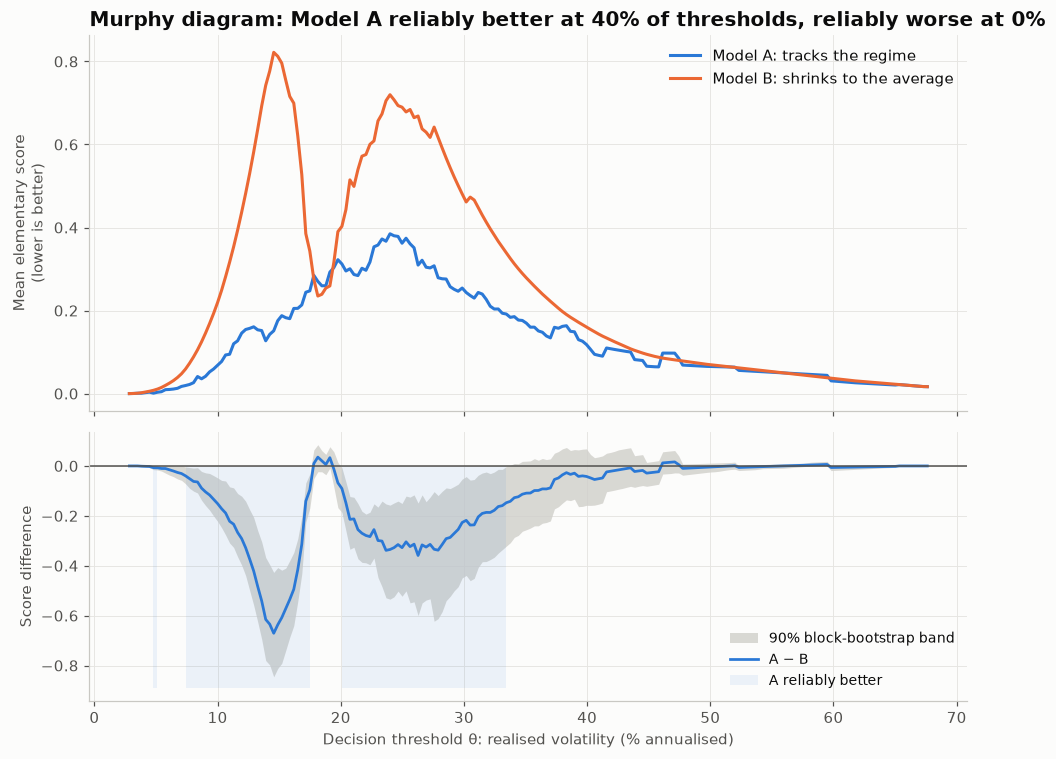

In [3]:
def elementary_scores(x, y, theta):
    """Elementary score for the mean (expectile at level 1/2), one column per threshold."""
    X, Y, T = x[:, None], y[:, None], theta[None, :]
    return np.abs((Y < X) - 0.5) * (np.maximum(Y - T, 0) - np.maximum(X - T, 0) - (Y - X) * (T < X))

y = df["realised"].to_numpy()
theta = np.linspace(np.percentile(y, 0.5) * 0.8, np.percentile(y, 99.5) * 1.1, 200)
score_a = elementary_scores(df["model_a"].to_numpy(), y, theta)
score_b = elementary_scores(df["model_b"].to_numpy(), y, theta)
diff = score_a - score_b

# 90% pointwise band from a moving-block bootstrap (12-month blocks keep the autocorrelation).
rng_boot = np.random.default_rng(3)
block = 12
starts = rng_boot.integers(0, n - block, size=(400, n // block))
boot = np.array([diff[(s[:, None] + np.arange(block)).ravel()].mean(0) for s in starts])
lo, hi = np.quantile(boot, [0.05, 0.95], axis=0)

fig, (ax, axd) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, height_ratios=[1.4, 1])
ax.plot(theta, score_a.mean(0), color=PALETTE[0], label="Model A: tracks the regime")
ax.plot(theta, score_b.mean(0), color=PALETTE[1], label="Model B: shrinks to the average")
ax.set_ylabel("Mean elementary score\n(lower is better)")
better, worse = hi < 0, lo > 0
ax.set_title(f"Murphy diagram: Model A reliably better at {better.mean():.0%} of thresholds, "
             f"reliably worse at {worse.mean():.0%}")
ax.legend(loc="upper right")

axd.fill_between(theta, lo, hi, color="#d0cfca", alpha=0.8, linewidth=0, label="90% block-bootstrap band")
axd.plot(theta, diff.mean(0), color=PALETTE[0], linewidth=1.8, label="A − B")
axd.fill_between(theta, axd.get_ylim()[0], 0, where=better, color=PALETTE[0], alpha=0.08,
                 linewidth=0, label="A reliably better")
axd.axhline(0, color="#52514e", linewidth=1)
axd.set_xlabel("Decision threshold θ: realised volatility (% annualised)")
axd.set_ylabel("Score difference")
axd.legend(loc="lower right", fontsize=9)
fig.tight_layout()
plt.show()

## How to read it

Top: Model A's curve (blue) is at or below Model B's (orange) almost everywhere, so A is the better forecast for almost any user, whatever their loss function. Bottom: the difference A − B with a 90% block-bootstrap band. In the shaded thresholds A is reliably better (mostly well away from the long-run average, where shrinking towards it hurts); nowhere is B reliably better. Near the long-run average the two forecasts are indistinguishable.

## Reference

This method comes from the research literature:

- Ehm, W., Gneiting, T., Jordan, A. & Krüger, F. (2016). Of quantiles and expectiles: consistent scoring functions, Choquet representations and forecast rankings. Journal of the Royal Statistical Society Series B 78(3), 505–562. <https://doi.org/10.1111/rssb.12154>

---
Standalone script: [`murphy_diagram.py`](murphy_diagram.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)